# Guía 6 – 3.2 Regresión Logística
**Producto de datos:** apoyo al diagnóstico de tumores de mama (maligno / benigno).

**Objetivo:** clasificar tumores con regresión logística usando `load_breast_cancer` de sklearn. Variable objetivo `target`: **0 = maligno, 1 = benigno**. Test set 30 %, `random_state=10`, variables escaladas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, classification_report)

sns.set_theme(style="whitegrid")

## 1. Carga y exploración

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame
print(df.shape)
print("Nombres de clase (0, 1):", list(data.target_names))
df["target"].value_counts().rename({0: "0 = maligno", 1: "1 = benigno"}).to_frame("n")

(569, 31)
Nombres de clase (0, 1): [np.str_('malignant'), np.str_('benign')]


,n
target,
1 = benigno,357
0 = maligno,212


In [3]:
print("Nulos:", df.isna().sum().sum())
df.iloc[:, :8].describe().T

Nulos: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.1307,0.4268
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.0740,0.2012


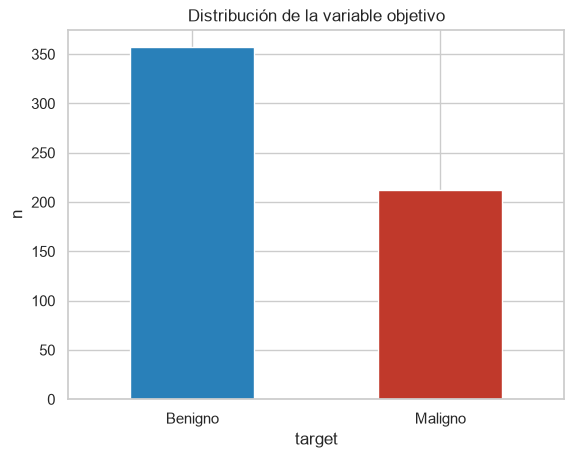

In [4]:
df["target"].map({0: "Maligno", 1: "Benigno"}).value_counts().plot.bar(color=["#2980b9", "#c0392b"])
plt.title("Distribución de la variable objetivo"); plt.ylabel("n"); plt.xticks(rotation=0); plt.show()

## 2. Partición y escalado
Las 30 variables tienen escalas muy distintas (p. ej. `mean area` ~ 650 vs `mean smoothness` ~ 0.1). La regresión logística usa regularización y un optimizador sensible a la escala, por eso se estandariza.

Para evitar *data leakage*, el `StandardScaler` se **ajusta solo con Train** y luego se aplica a Test.

In [5]:
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=10)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)

Train: (398, 30) | Test: (171, 30)


## 3. Entrenamiento

In [6]:
modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train_s, y_train)

pred = modelo.predict(X_test_s)
proba = modelo.predict_proba(X_test_s)[:, 1]

## 4. Evaluación en Test

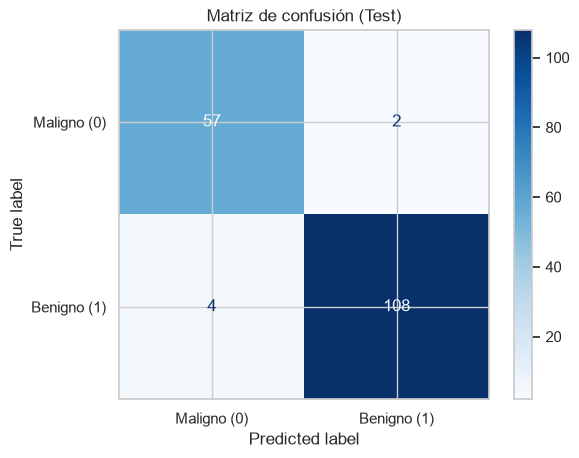

[[ 57   2]
 [  4 108]]


In [7]:
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=["Maligno (0)", "Benigno (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión (Test)"); plt.show()
print(cm)

In [8]:
# Clase positiva = 1 (benigno), que es la convención de sklearn por defecto
metricas = pd.Series({
    "Accuracy":  accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "Recall":    recall_score(y_test, pred),
    "F1":        f1_score(y_test, pred),
})
metricas.round(4).to_frame("valor")

,valor
Accuracy,0.9649
Precision,0.9818
Recall,0.9643
F1,0.9730


In [9]:
# Vista clínica: clase de interés = maligno (0)
print(f"Malignos clasificados como benignos (falsos negativos clínicos): {cm[0, 1]}")
print(f"Benignos clasificados como malignos (falsos positivos clínicos): {cm[1, 0]}")
print(f"Recall de maligno    = {recall_score(y_test, pred, pos_label=0):.4f}")
print(f"Precision de maligno = {precision_score(y_test, pred, pos_label=0):.4f}")
print()
print(classification_report(y_test, pred, target_names=["Maligno", "Benigno"]))

Malignos clasificados como benignos (falsos negativos clínicos): 2
Benignos clasificados como malignos (falsos positivos clínicos): 4
Recall de maligno    = 0.9661
Precision de maligno = 0.9344

              precision    recall  f1-score   support

     Maligno       0.93      0.97      0.95        59
     Benigno       0.98      0.96      0.97       112

    accuracy                           0.96       171
   macro avg       0.96      0.97      0.96       171
weighted avg       0.97      0.96      0.97       171



## 5. Variables más influyentes

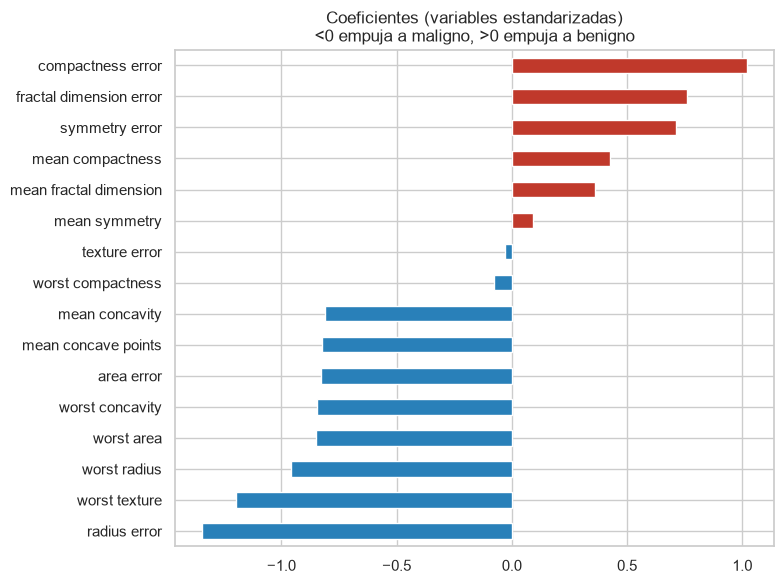

In [10]:
coef = pd.Series(modelo.coef_[0], index=data.feature_names).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
top.plot.barh(figsize=(8, 6), color=np.where(top < 0, "#2980b9", "#c0392b"))
plt.title("Coeficientes (variables estandarizadas)\n<0 empuja a maligno, >0 empuja a benigno")
plt.tight_layout(); plt.show()

## 6. Interpretación
**Resultados (Test, 171 pacientes):** Accuracy = **0.9649**, Precision = **0.9818**, Recall = **0.9643**, F1 = 0.9730 (clase positiva = 1, benigno).

- **Matriz de confusión:** `[[57, 2], [4, 108]]` → 57 malignos bien detectados, 108 benignos bien detectados, 2 malignos clasificados como benignos y 4 benignos clasificados como malignos. 6 errores de 171.
- **Accuracy 96.5 %:** la clase mayoritaria (benigno) representa 65.5 % del Test, así que el modelo supera con claridad a un clasificador trivial que siempre diga "benigno".
- **Precision (benigno) 98.2 %:** de los casos que el modelo llama benignos, el 98 % lo es; el 2 % restante son los 2 malignos que se escapan.
- **Recall (benigno) 96.4 %:** detecta 108 de 112 benignos; los 4 restantes son falsas alarmas que llevarían a pruebas adicionales.
- **Lectura clínica:** el error más costoso es el falso negativo (maligno → benigno): hay 2. El recall de la clase maligno es 96.6 % (precision 93.4 %). En un producto real convendría bajar el umbral de `predict_proba` para subir ese recall, aceptando más falsas alarmas.
- **Coeficientes:** al estar estandarizadas, su magnitud es comparable. Los más negativos (empujan a maligno) son `radius error`, `worst texture`, `worst radius`, `worst area` y `worst concavity`: tumores grandes, irregulares y con concavidad marcada. Con 30 variables correlacionadas entre sí, algunos coeficientes positivos (p. ej. `compactness error`) son un efecto de colinealidad y no deben interpretarse de forma aislada.

**Conclusión:** un modelo simple e interpretable separa muy bien ambas clases, con solo 6 errores en 171 casos. Es una base sólida para compararlo con los demás modelos del trabajo.